# Моделирование: Bank Marketing — Левин
Предсказываем, согласится ли клиент на депозит (`y`). Опираемся на выводы EDA ([eda_levin.ipynb](eda_levin.ipynb)):
- `duration` — утечка, в основной модели не используем;
- конверсия дрейфует по времени (≈5% → 17% → 52% по годам), поэтому считаем **три** схемы валидации;
- пропуски — осмысленные категории, а не «дыры».

**План:** 1) валидация и метрики → 2) фичи → 3) модели → 4) гипотезы по фичам → 5) сравнение моделей → 6) тюнинг → 7) дисбаланс: веса, сэмплинг, синтетика → 8) финальная модель → 9) порог и цена ошибок → 10) вердикт.

## 0. Импорты и данные

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from ucimlrepo import fetch_ucirepo

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold, TimeSeriesSplit, GroupKFold, ParameterSampler
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

sns.set_theme(style='whitegrid'); pd.set_option('display.width', 140, 'display.max_columns', 40)
SEED, N_JOBS = 42, 8
N_ITER = 30   # число конфигураций в random search

In [2]:
bm = fetch_ucirepo(id=222)
raw = pd.concat([bm.data.features, bm.data.targets], axis=1)
y = (raw.y == 'yes').astype(int).values
print(raw.shape, f'| доля yes: {y.mean():.3f}')

MONTHS = {m: i + 1 for i, m in enumerate('jan feb mar apr may jun jul aug sep oct nov dec'.split())}
YEAR = 2008 + (raw.month.map(MONTHS).diff().fillna(0) < 0).cumsum().values   # год из порядка строк (EDA 2.2)
PERIOD = YEAR * 100 + raw.month.map(MONTHS).values                            # группа «год-месяц»

(45211, 17) | доля yes: 0.117


## 1. Валидация и метрики
Классы несбалансированы (≈12% «да»), поэтому accuracy не используем. Метрики:
- **ROC-AUC** — качество ранжирования клиентов;
- **PR-AUC** (average precision) — то же, но с упором на редкий класс; базовый уровень = доля «да» (≈0.12);
- **Lift@10%** — во сколько раз доля «да» среди 10% самых «вероятных» клиентов выше средней. Бизнес-смысл: «если обзванивать только топ-10% по модели».

Три схемы (все 5 фолдов):
- **strat** — стандартная Stratified K-fold с перемешиванием. Соседние по времени клиенты попадают и в train, и в test, поэтому оценка **оптимистична**;
- **block** — GroupKFold по периодам «год-месяц»: тест — месяцы, которых нет в train (но обучаемся и на прошлом, и на будущем). Проверяет устойчивость к смене периода;
- **time** — forward-chaining (`TimeSeriesSplit`): учимся на прошлом, тестируем на будущем. Самая строгая, но в ранних фолдах мало данных для обучения.

In [3]:
class BlockCV:   # GroupKFold по периодам; обёртка, чтобы split(X, y) не требовал groups
    def __init__(self, groups, n=5): self.groups, self.n = groups, n
    def split(self, X, y=None): return GroupKFold(self.n).split(X, y, self.groups)

skf, tss = StratifiedKFold(5, shuffle=True, random_state=SEED), TimeSeriesSplit(n_splits=5)
SCHEMES = {'strat': skf, 'block': BlockCV(PERIOD), 'time': tss}

def lift_at(y_true, p, frac=0.10):
    k = int(len(y_true) * frac)
    return y_true[np.argsort(-p)[:k]].mean() / y_true.mean()

def score_oof(y_true, oof, fold):
    # метрики по каждому фолду (только по тестовым строкам), затем среднее
    rows = []
    for f in sorted(set(fold[fold >= 0])):
        m = fold == f
        rows.append((roc_auc_score(y_true[m], oof[m]), average_precision_score(y_true[m], oof[m]), lift_at(y_true[m], oof[m])))
    return pd.DataFrame(rows, columns=['auc', 'pr', 'lift10'])

def evaluate(make, X, cv):
    # make(X) -> новая модель; возвращает метрики по фолдам и out-of-fold предсказания
    oof, fold = np.full(len(y), np.nan), np.full(len(y), -1)
    for i, (tr, te) in enumerate(cv.split(X, y)):
        m = make(X).fit(X.iloc[tr], y[tr])
        oof[te], fold[te] = m.predict_proba(X.iloc[te])[:, 1], i
    return score_oof(y, oof, fold), oof, fold

def both(make, X):
    # прогон по всем схемам, сводка в одну строку
    res = {k: evaluate(make, X, cv) for k, cv in SCHEMES.items()}
    row = {f'{k}_{m}': res[k][0][m].mean() for k in SCHEMES for m in ('auc', 'pr', 'lift10')}
    return row, res

## 2. Фичи
Все фичи считаются **построчно** (без таргета и без статистик по всей выборке) — значит, утечки через фичи нет.
Пропуски заполняем осмысленно (EDA, H1/H2): `poutcome=NaN` → `no_prev`, остальные → `unknown`.
Год **не используем** — в реальном применении «будущего года» нет (но проверим его как гипотезу в разделе 4).

| Фича | Идея (из EDA) |
|---|---|
| `prev_contacted`, `pdays_clean` | `pdays=-1` — маркер «не звонили»; отделяем флаг от числа дней |
| `prev_success` | `poutcome=success` → конверсия ≈65% |
| `contact_unknown` | пропуск `contact` (но он в основном прокси периода мая–июня 2008) |
| `month_num` | порядковый месяц |
| `age_bin` | U-образная зависимость от возраста |
| `balance_log`, `balance_neg` | скошенность, плато, отрицательные балансы |
| `n_loans` | сколько долговых флагов (`housing`, `loan`, `default`) |
| `campaign_clip`, `previous_clip` | обрезаем хвосты |
| `job_sr` | `student`/`retired` — самые конвертируемые |

In [4]:
CATS = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

def build(fe=True, duration=False, year=False, drop=()):
    d = raw.drop(columns='y').rename(columns={'day_of_week': 'day'}).copy()
    for c in CATS: d[c] = d[c].fillna('no_prev' if c == 'poutcome' else 'unknown')
    if fe:
        d['month_num'] = d.month.map(MONTHS)
        d['prev_contacted'] = (d.pdays != -1).astype(int)
        d['pdays_clean'] = d.pdays.where(d.pdays > 0)
        d['prev_success'] = (d.poutcome == 'success').astype(int)
        d['contact_unknown'] = (d.contact == 'unknown').astype(int)
        d['age_bin'] = pd.cut(d.age, [0, 25, 30, 40, 50, 60, 120], labels=['<=25', '26-30', '31-40', '41-50', '51-60', '60+']).astype(str)
        d['balance_log'] = np.sign(d.balance) * np.log1p(d.balance.abs())
        d['balance_neg'] = (d.balance < 0).astype(int)
        d['n_loans'] = (d.housing == 'yes').astype(int) + (d.loan == 'yes') + (d.default == 'yes')
        d['campaign_clip'] = d.campaign.clip(upper=10)
        d['previous_clip'] = d.previous.clip(upper=10)
        d['job_sr'] = d.job.isin(['student', 'retired']).astype(int)
        d = d.drop(columns='pdays')
    if year: d['year'] = YEAR
    if not duration: d = d.drop(columns='duration')
    d = d.drop(columns=list(drop))
    for c in [*CATS, 'age_bin']:
        if c in d: d[c] = d[c].astype('category')
    return d.reset_index(drop=True)

X_raw, X_fe = build(fe=False), build(fe=True)
print(X_raw.shape, X_fe.shape); X_fe.head(3)

(45211, 15) (45211, 26)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,previous,poutcome,month_num,prev_contacted,pdays_clean,prev_success,contact_unknown,age_bin,balance_log,balance_neg,n_loans,campaign_clip,previous_clip,job_sr
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,1,0,no_prev,5,0,NaN,0,1,51-60,7.670429,0,1,1,0,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,1,0,no_prev,5,0,NaN,0,1,41-50,3.401197,0,1,1,0,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,1,0,no_prev,5,0,NaN,0,1,31-40,1.098612,0,2,1,0,0


## 3. Модели
Линейная модель и лес получают one-hot, бустинги — категории нативно. Гиперпараметры пока «разумные по умолчанию»; тюнинг — в разделе 6.

In [5]:
def cats_nums(X):
    cats = [c for c in X if str(X[c].dtype) == 'category']; return cats, [c for c in X if c not in cats]

def prep_lin(X):
    cats, nums = cats_nums(X)
    return ColumnTransformer([('n', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), nums),
                              ('c', OneHotEncoder(handle_unknown='ignore', min_frequency=20), cats)])

def make_lr(X, C=0.3):   return make_pipeline(prep_lin(X), LogisticRegression(C=C, max_iter=3000))
def make_rf(X):          return make_pipeline(prep_lin(X), RandomForestClassifier(300, min_samples_leaf=20, n_jobs=N_JOBS, random_state=SEED))

LGB_P = dict(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=50, subsample=0.8, subsample_freq=1, colsample_bytree=0.8)
def make_lgb(X, **kw):   return LGBMClassifier(**{**LGB_P, **kw}, n_jobs=N_JOBS, random_state=SEED, verbose=-1)
def make_xgb(X):         return XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=5, subsample=0.8, colsample_bytree=0.8,
                                              enable_categorical=True, tree_method='hist', n_jobs=N_JOBS, random_state=SEED)
def make_cat(X):
    cats, _ = cats_nums(X)
    to_str = FunctionTransformer(lambda d: d.astype({c: str for c in cats}))   # CatBoost хочет строки
    return make_pipeline(to_str, CatBoostClassifier(iterations=500, learning_rate=0.05, depth=6, cat_features=cats,
                                                     thread_count=N_JOBS, random_seed=SEED, verbose=0))

## 4. Гипотезы по фичам (ablation)
Меняем **одну вещь** относительно базы (LightGBM + фичи из раздела 2) и смотрим на три схемы. Разница < ~0.005 AUC — в пределах шума.

Главный вопрос, который поставил EDA: признаки `month`, `day`, `contact_unknown` (и категория `contact=unknown`) — это **прокси периода** (май–июнь 2008 и т.п.). Помогают ли они предсказывать *новый* период или только «запоминают» старый?

In [6]:
PROXY = ['month', 'month_num', 'day', 'contact_unknown']
base = both(make_lgb, X_fe)[0]
exps = {
 'H1. сырые признаки вместо fe':                          (make_lgb, X_raw),
 'H2. + duration (утечка, потолок)':                      (make_lgb, build(duration=True)),
 'H3. + год (прокси дрейфа)':                             (make_lgb, build(year=True)),
 'H4a. без прокси времени (month, day, contact_unknown)': (make_lgb, build(drop=PROXY)),
 'H4b. + без contact (в нём «unknown» = май–июнь 2008)':  (make_lgb, build(drop=PROXY + ['contact'])),
 'H5. без слабых (default, marital, education, loan)':    (make_lgb, build(drop=['default', 'marital', 'education', 'loan'])),
 'H6. без дублей (age_bin, balance_log, *_clip)':         (make_lgb, build(drop=['age_bin', 'balance_log', 'campaign_clip', 'previous_clip'])),
 'H7. веса классов (is_unbalance)':                       (lambda X: make_lgb(X, is_unbalance=True), X_fe),
 'H8. мелкие деревья (num_leaves=7, 500 шт.)':            (lambda X: make_lgb(X, num_leaves=7, n_estimators=500), X_fe),
}
out = [{'эксперимент': 'БАЗА: LightGBM + fe', **base}]
for k, (mk, X) in exps.items(): out.append({'эксперимент': k, **both(mk, X)[0]})
hyp = pd.DataFrame(out).set_index('эксперимент')
auc = hyp[['strat_auc', 'block_auc', 'time_auc']]
pd.concat([auc.round(3), auc.sub(auc.iloc[0]).add_prefix('Δ ').round(3), hyp[['strat_lift10', 'block_lift10', 'time_lift10']].round(2)], axis=1)

,strat_auc,block_auc,time_auc,Δ strat_auc,Δ block_auc,Δ time_auc,strat_lift10,block_lift10,time_lift10
эксперимент,,,,,,,,,
БАЗА: LightGBM + fe,0.803,0.655,0.574,0.000,0.000,0.000,4.45,2.97,1.35
H1. сырые признаки вместо fe,0.803,0.653,0.563,0.000,-0.003,-0.012,4.43,2.96,1.28
"H2. + duration (утечка, потолок)",0.939,0.823,0.872,0.136,0.168,0.298,5.45,3.91,5.40
H3. + год (прокси дрейфа),0.811,0.730,0.575,0.008,0.074,0.000,4.57,3.66,1.37
"H4a. без прокси времени (month, day, contact_unknown)",0.758,0.723,0.569,-0.045,0.068,-0.006,3.79,3.71,1.41
H4b. + без contact (в нём «unknown» = май–июнь 2008),0.737,0.719,0.574,-0.065,0.063,-0.000,3.72,3.61,1.48
"H5. без слабых (default, marital, education, loan)",0.798,0.646,0.565,-0.004,-0.009,-0.009,4.42,2.98,1.29
"H6. без дублей (age_bin, balance_log, *_clip)",0.803,0.662,0.579,0.000,0.007,0.005,4.43,3.08,1.41
H7. веса классов (is_unbalance),0.801,0.660,0.565,-0.002,0.004,-0.009,4.39,3.19,1.27


**Как читать:** `Δ` — разница AUC с базой; справа Lift@10%.
- **H2** — «цена» утечки `duration`: огромный скачок на всех схемах (его нельзя использовать).
- **H3/H4** — признаки периода по-разному ведут себя в схемах: случайная CV (`strat`) их «любит» (они позволяют запомнить период), а схемы со сдвигом периода (`block`, `time`) — нет.

In [7]:
# Выбираем набор фичей по схемам со сдвигом периода (block и time); strat — только справка
shift = lambda r: (r.block_auc + r.time_auc) / 2
cand = {'fe (все фичи)': ([], shift(hyp.iloc[0])), 'без прокси': (PROXY, shift(hyp.loc['H4a. без прокси времени (month, day, contact_unknown)'])),
        'без прокси и contact': (PROXY + ['contact'], shift(hyp.loc['H4b. + без contact (в нём «unknown» = май–июнь 2008)']))}
NP_NAME = max(cand, key=lambda k: cand[k][1]); NP_DROP = cand[NP_NAME][0]
print({k: round(v[1], 4) for k, v in cand.items()}); print('Выбран набор:', NP_NAME)
X_np = build(drop=NP_DROP); print(X_np.shape)

{'fe (все фичи)': np.float64(0.615), 'без прокси': np.float64(0.6461), 'без прокси и contact': np.float64(0.6466)}
Выбран набор: без прокси и contact
(45211, 21)


## 5. Сравнение моделей
Все модели на двух наборах: `fe` (все фичи) и `np` (выбранный устойчивый набор без прокси периода).

In [8]:
runs = {}
def run(name, make, X):
    row, res = both(make, X); runs[name] = res; return {'model': name, **row}

makers = {'LogReg': make_lr, 'RandomForest': make_rf, 'LightGBM': make_lgb, 'XGBoost': make_xgb, 'CatBoost': make_cat}
rows = [run(f'{n} ({tag})', mk, X) for tag, X in [('fe', X_fe), ('np', X_np)] for n, mk in makers.items()]
cmp = pd.DataFrame(rows).set_index('model'); cmp.round(3)

,strat_auc,strat_pr,strat_lift10,block_auc,block_pr,block_lift10,time_auc,time_pr,time_lift10
model,,,,,,,,,
LogReg (fe),0.773,0.412,4.166,0.669,0.327,3.342,0.598,0.192,1.552
RandomForest (fe),0.797,0.437,4.240,0.676,0.338,3.432,0.588,0.183,1.458
LightGBM (fe),0.803,0.459,4.450,0.655,0.294,2.968,0.574,0.183,1.353
XGBoost (fe),0.803,0.459,4.418,0.653,0.295,2.938,0.578,0.181,1.276
CatBoost (fe),0.803,0.455,4.386,0.654,0.306,3.075,0.579,0.187,1.429
LogReg (np),0.736,0.372,3.659,0.722,0.366,3.627,0.607,0.207,1.689
RandomForest (np),0.741,0.381,3.780,0.722,0.374,3.789,0.599,0.190,1.578
LightGBM (np),0.737,0.383,3.724,0.719,0.366,3.609,0.574,0.186,1.477
XGBoost (np),0.739,0.383,3.729,0.722,0.372,3.666,0.576,0.186,1.484


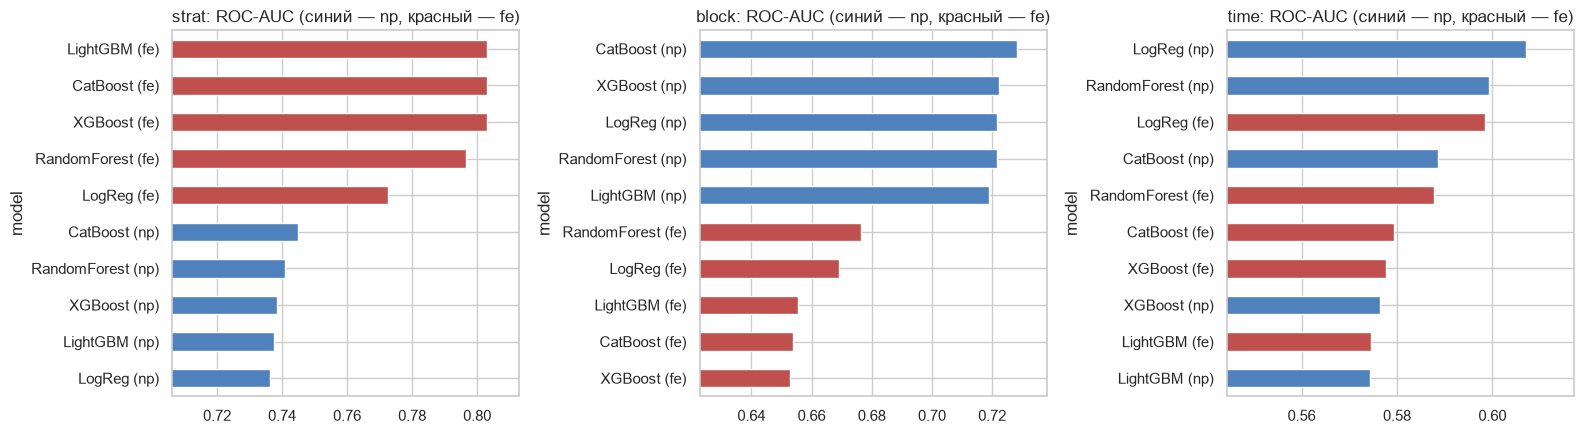

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, k in zip(axs, ['strat', 'block', 'time']):
    cmp[f'{k}_auc'].sort_values().plot.barh(ax=ax, color=['#c0504d' if 'fe)' in i else '#4f81bd' for i in cmp[f'{k}_auc'].sort_values().index])
    ax.set_title(f'{k}: ROC-AUC (синий — np, красный — fe)'); ax.set_xlim(cmp[f'{k}_auc'].min() - .03, cmp[f'{k}_auc'].max() + .01)
plt.tight_layout(); plt.show()

## 6. Тюнинг LightGBM
Random search на наборе `np`; конфигурацию оцениваем по **среднему AUC схем block и time** (устойчивость к сдвигу периода).

In [10]:
space = dict(n_estimators=[150, 250, 400, 600], learning_rate=[0.02, 0.03, 0.05, 0.08], num_leaves=[3, 4, 7, 15, 31],
             min_child_samples=[20, 50, 100, 200, 400], subsample=[0.6, 0.8, 1.0], colsample_bytree=[0.5, 0.7, 0.9],
             reg_lambda=[0, 1, 5, 20, 50], max_cat_to_onehot=[4, 8, 16], cat_smooth=[10, 30, 100])
cands, tune = list(ParameterSampler(space, N_ITER, random_state=SEED)), []
for p in cands:
    r, _ = both(lambda X: make_lgb(X, **p), X_np)
    tune.append({**r, 'score': (r['block_auc'] + r['time_auc']) / 2})
tune = pd.DataFrame(tune).sort_values('score', ascending=False)
pd.concat([pd.DataFrame(cands).loc[tune.index], tune], axis=1).head(5).round(4)

,subsample,reg_lambda,num_leaves,n_estimators,min_child_samples,max_cat_to_onehot,learning_rate,colsample_bytree,cat_smooth,strat_auc,strat_pr,strat_lift10,block_auc,block_pr,block_lift10,time_auc,time_pr,time_lift10,score
5,0.6,1,4,400,100,8,0.02,0.5,100,0.7439,0.3833,3.8108,0.7246,0.3738,3.7894,0.6050,0.1971,1.5892,0.6648
24,0.8,50,4,400,50,16,0.05,0.7,30,0.7449,0.3882,3.7862,0.7271,0.3788,3.7886,0.6017,0.1951,1.5371,0.6644
14,1.0,1,4,150,50,8,0.05,0.5,30,0.7434,0.3828,3.8108,0.7233,0.3713,3.7739,0.6047,0.2006,1.6368,0.6640
0,1.0,5,3,400,50,4,0.08,0.5,100,0.7442,0.3884,3.8108,0.7252,0.3774,3.7500,0.6027,0.1985,1.6183,0.6640
7,0.6,50,3,600,100,8,0.05,0.7,100,0.7442,0.3865,3.7937,0.7265,0.3765,3.7519,0.6012,0.1953,1.6308,0.6638


In [11]:
best = cands[tune.index[0]]; d0 = cmp.loc['LightGBM (np)']
print('Лучшие параметры:', best)
print(f"Тюнинг: score {tune.score.iloc[0]:.4f} vs дефолт {(d0.block_auc + d0.time_auc) / 2:.4f}")

Лучшие параметры: {'subsample': 0.6, 'reg_lambda': 1, 'num_leaves': 4, 'n_estimators': 400, 'min_child_samples': 100, 'max_cat_to_onehot': 8, 'learning_rate': 0.02, 'colsample_bytree': 0.5, 'cat_smooth': 100}
Тюнинг: score 0.6648 vs дефолт 0.6466


## 7. Дисбаланс классов: ресэмплинг, веса, синтетика
Аудит требований проекта к дисбалансу (12% «да»):

| Требование | Где закрыто |
|---|---|
| Дисбаланс классов | EDA (п. 3), метрики PR-AUC и Lift вместо accuracy |
| Разбиение с учётом пропорции | схема `strat` (StratifiedKFold) и стратифицированный hold-out в п. 9. Схемы `block`/`time` стратифицировать нельзя (периоды важнее) — доля «да» в их фолдах плавает |
| Признаки через призму целевых классов | EDA (конверсия по группам) + распределения по классам в п. 8 |
| Дисбаланс ошибок, порог, цена ошибок | п. 9 |
| Взвешивание классов | H7 (`is_unbalance`) + здесь шире |
| Синтетика, урезание, разные сэмплинги | здесь |

Ресэмплинг делаем **только на обучающей части каждого фолда** (иначе утечка), тест остаётся с реальной долей «да».
Кроме ранжирующих метрик смотрим **Brier** (качество вероятностей: ресэмплинг их искажает) и **max F1** (лучший порог).

In [12]:
from imblearn.over_sampling import RandomOverSampler, SMOTENC
from imblearn.under_sampling import RandomUnderSampler
from sklearn.metrics import brier_score_loss, precision_recall_curve

class SampledLGB:
    # LightGBM + ресэмплинг на train-части фолда. Категории -> коды (нужно для SMOTENC), NaN -> -1
    def __init__(self, X, sampler=None, **kw):
        self.cats = [c for c in X if str(X[c].dtype) == 'category']; self.levels = {c: X[c].cat.categories for c in self.cats}
        self.cols, self.sampler, self.kw = list(X.columns), sampler, kw
    def _enc(self, X):
        Z = X.copy()
        for c in self.cats: Z[c] = Z[c].cat.codes
        return Z.fillna(-1).values
    def _dec(self, Z):
        Z = pd.DataFrame(Z, columns=self.cols)
        for c in self.cats: Z[c] = pd.Categorical.from_codes(Z[c].round().astype(int), categories=self.levels[c])
        return Z
    def fit(self, X, y_):
        Z = self._enc(X)
        if self.sampler is not None: Z, y_ = self.sampler.fit_resample(Z, y_)
        self.m = make_lgb(X, **{**best, **self.kw}).fit(self._dec(Z), y_); return self
    def predict_proba(self, X): return self.m.predict_proba(self._dec(self._enc(X)))

# индексы «категориальных» колонок для SMOTENC: категории + бинарные флаги
cat_idx = [i for i, c in enumerate(X_np) if str(X_np[c].dtype) == 'category' or X_np[c].nunique() <= 2]
spw = float(np.sqrt((1 - y.mean()) / y.mean()))   # смягчённый вес положительного класса

samplers = {
    'без балансировки':          lambda: dict(),
    'class_weight=balanced':     lambda: dict(class_weight='balanced'),
    'вес класса ~ sqrt(ratio)':  lambda: dict(scale_pos_weight=spw),
    'undersample 1:1':           lambda: dict(sampler=RandomUnderSampler(random_state=SEED)),
    'undersample 1:3':           lambda: dict(sampler=RandomUnderSampler(sampling_strategy=1/3, random_state=SEED)),
    'oversample 1:1':            lambda: dict(sampler=RandomOverSampler(random_state=SEED)),
    'SMOTENC (до 1:2)':          lambda: dict(sampler=SMOTENC(categorical_features=cat_idx, sampling_strategy=0.5, random_state=SEED)),
}

In [13]:
def extra(res):
    # Brier и лучший F1 (по порогу) в среднем по фолдам каждой схемы
    out = {}
    for k, (_, o, f) in res.items():
        b, f1 = [], []
        for i in sorted(set(f[f >= 0])):
            m = f == i; pr, rc, _ = precision_recall_curve(y[m], o[m])
            b.append(brier_score_loss(y[m], o[m])); f1.append(np.max(2 * pr * rc / (pr + rc + 1e-12)))
        out[f'{k}_brier'], out[f'{k}_f1max'] = np.mean(b), np.mean(f1)
    return out

rows, samp_runs = [], {}
for name, cfg in samplers.items():
    row, res = both(lambda X: SampledLGB(X, **cfg()), X_np); samp_runs[name] = res
    rows.append({'метод': name, **row, **extra(res)})
smp = pd.DataFrame(rows).set_index('метод')
display(smp[[f'{k}_{m}' for m in ('auc', 'pr', 'lift10') for k in SCHEMES]].round(3))
display(smp[[f'{k}_{m}' for m in ('brier', 'f1max') for k in SCHEMES]].round(3))

,strat_auc,block_auc,time_auc,strat_pr,block_pr,time_pr,strat_lift10,block_lift10,time_lift10
метод,,,,,,,,,
без балансировки,0.744,0.725,0.604,0.380,0.371,0.195,3.809,3.786,1.551
class_weight=balanced,0.744,0.724,0.600,0.379,0.370,0.193,3.803,3.737,1.514
вес класса ~ sqrt(ratio),0.744,0.724,0.602,0.380,0.371,0.194,3.788,3.775,1.516
undersample 1:1,0.742,0.720,0.588,0.377,0.365,0.179,3.737,3.704,1.417
undersample 1:3,0.744,0.722,0.596,0.381,0.367,0.189,3.801,3.745,1.519
oversample 1:1,0.743,0.723,0.601,0.379,0.369,0.198,3.799,3.744,1.569
SMOTENC (до 1:2),0.727,0.717,0.549,0.366,0.364,0.173,3.580,3.631,1.193


,strat_brier,block_brier,time_brier,strat_f1max,block_f1max,time_f1max
метод,,,,,,
без балансировки,0.088,0.089,0.107,0.417,0.411,0.255
class_weight=balanced,0.190,0.206,0.226,0.416,0.410,0.251
вес класса ~ sqrt(ratio),0.104,0.111,0.101,0.416,0.411,0.253
undersample 1:1,0.191,0.209,0.246,0.411,0.403,0.249
undersample 1:3,0.101,0.108,0.124,0.417,0.408,0.253
oversample 1:1,0.190,0.206,0.228,0.416,0.409,0.254
SMOTENC (до 1:2),0.096,0.099,0.107,0.398,0.406,0.235


**Как читать:** AUC / PR / Lift — качество *ранжирования*; Brier — качество *вероятностей* (меньше = лучше); max F1 — лучшее достижимое F1 при подборе порога.
Ожидание: балансировка не должна улучшать ранжирование (для этого она не нужна), но сильно портит калибровку вероятностей; единственное, где она может помочь — при **фиксированном пороге 0.5**. Это мы проверим в п. 9, где порог подбирается явно.

## 8. Финальная модель: один тюнёный LightGBM (без ансамблей)
Набор фичей `np` (без `duration` и прокси периода), параметры из п. 6, без ресэмплинга и весов — по результатам п. 7.

In [14]:
final_row, final = both(lambda X: make_lgb(X, **best), X_np)
for s in SCHEMES:
    t = final[s][0].copy(); f = final[s][2]; ids = sorted(set(f[f >= 0]))
    t['тест, n'] = [(f == i).sum() for i in ids]; t['доля yes в тесте'] = [y[f == i].mean() for i in ids]
    print(f'Схема {s}: по фолдам (PR-AUC между фолдами сравнивать нельзя — разная доля yes)'); display(t.round(3))
pd.DataFrame({s: final[s][0].mean() for s in SCHEMES}).T.assign(**{'baseline PR': y.mean()}).round(3)

Схема strat: по фолдам (PR-AUC между фолдами сравнивать нельзя — разная доля yes)


,auc,pr,lift10,"тест, n",доля yes в тесте
0,0.733,0.372,3.602,9043,0.117
1,0.755,0.395,4.050,9042,0.117
2,0.740,0.383,3.800,9042,0.117
3,0.728,0.360,3.592,9042,0.117
4,0.764,0.407,4.008,9042,0.117


Схема block: по фолдам (PR-AUC между фолдами сравнивать нельзя — разная доля yes)


,auc,pr,lift10,"тест, n",доля yes в тесте
0,0.816,0.491,5.534,9054,0.091
1,0.709,0.323,3.498,9059,0.112
2,0.640,0.276,2.477,8998,0.142
3,0.745,0.404,3.542,9073,0.140
4,0.713,0.375,3.896,9027,0.100


Схема time: по фолдам (PR-AUC между фолдами сравнивать нельзя — разная доля yes)


,auc,pr,lift10,"тест, n",доля yes в тесте
0,0.565,0.065,1.698,7535,0.052
1,0.554,0.073,1.197,7535,0.062
2,0.557,0.069,1.225,7535,0.059
3,0.673,0.257,2.250,7535,0.136
4,0.675,0.522,1.576,7535,0.363


,auc,pr,lift10,baseline PR
strat,0.744,0.383,3.811,0.117
block,0.725,0.374,3.789,0.117
time,0.605,0.197,1.589,0.117


In [15]:
# Sanity-check: на перемешанном таргете AUC ≈ 0.5, и повторная стратифицированная CV 5x3
y_perm = np.random.default_rng(SEED).permutation(y)
a = [roc_auc_score(y_perm[te], make_lgb(X_np, **best).fit(X_np.iloc[tr], y_perm[tr]).predict_proba(X_np.iloc[te])[:, 1]) for tr, te in skf.split(X_np, y)]
print(f'Перемешанный таргет: AUC = {np.mean(a):.3f}  (ожидаем ≈ 0.5)')
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
aucs = [roc_auc_score(y[te], make_lgb(X_np, **best).fit(X_np.iloc[tr], y[tr]).predict_proba(X_np.iloc[te])[:, 1]) for tr, te in rskf.split(X_np, y)]
print(f'strat 5x3: AUC = {np.mean(aucs):.4f} ± {np.std(aucs):.4f}')

Перемешанный таргет: AUC = 0.505  (ожидаем ≈ 0.5)


strat 5x3: AUC = 0.7441 ± 0.0092


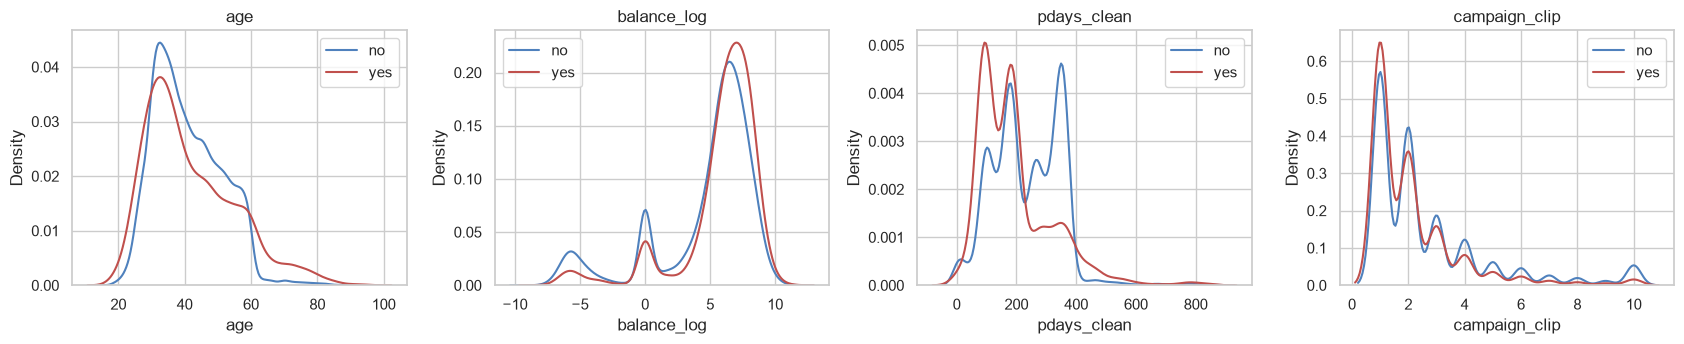

In [16]:
# Признаки через призму классов: распределения числовых признаков у «да» и «нет» (нормировано внутри класса)
fig, axs = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, c in zip(axs, ['age', 'balance_log', 'pdays_clean', 'campaign_clip']):
    for cls, col in [(0, '#4f81bd'), (1, '#c0504d')]:
        sns.kdeplot(X_np.loc[y == cls, c].dropna(), ax=ax, color=col, label='yes' if cls else 'no', common_norm=False, warn_singular=False)
    ax.set_title(c); ax.legend()
plt.tight_layout(); plt.show()

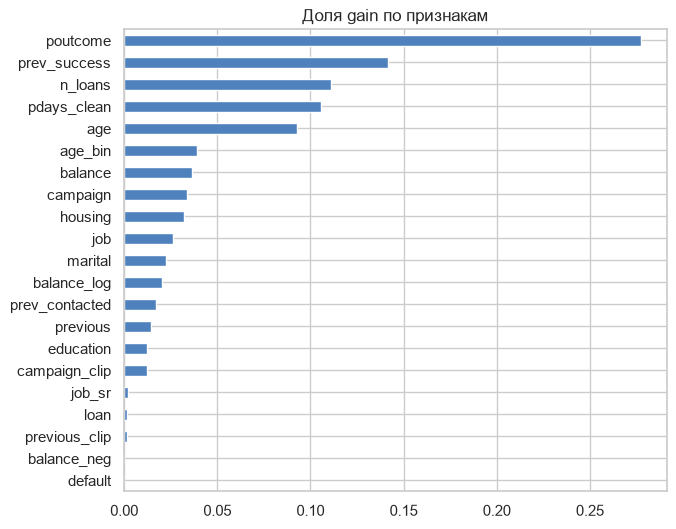

In [17]:
# Важность признаков (gain) на всех данных
m = make_lgb(X_np, **best).fit(X_np, y)
imp = pd.Series(m.booster_.feature_importance('gain'), index=X_np.columns).sort_values()
(imp / imp.sum()).plot.barh(figsize=(7, 6), color='#4f81bd'); plt.title('Доля gain по признакам'); plt.show()

## 9. Порог, цена ошибок и дисбаланс ошибок
Ранжирование (AUC) ещё не решение: нужно выбрать **порог** — кому звонить. Ошибки неравноценны:
- **FP** (позвонили тому, кто не купит) — стоит одного звонка, `c`;
- **FN** (не позвонили тому, кто купил) — упущенная прибыль `r` (минус стоимость звонка).

Реальных цифр у нас нет, поэтому берём **иллюстративные** значения: звонок стоит `c = 1`, подписка приносит `r` единиц, смотрим `r/c` = 5, 8, 12.
Если вероятности откалиброваны, оптимальный порог ≈ `c/r`, а «звонить всем» выгодно только при `r/c > 1/доля_yes ≈ 8.5`.

**Протокол (без подглядывания):** стратифицированный hold-out 80/20; порог выбираем по out-of-fold предсказаниям **на train**, а оцениваем **на test**.

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
Xtr, Xte, ytr, yte = train_test_split(X_np, y, test_size=0.2, stratify=y, random_state=SEED)
print(f'train {len(ytr)} / test {len(yte)}; доля yes: {ytr.mean():.3f} / {yte.mean():.3f}  (стратификация сохранила пропорцию)')

oof_tr = np.zeros(len(ytr))
for tr, te in skf.split(Xtr, ytr): oof_tr[te] = make_lgb(Xtr, **best).fit(Xtr.iloc[tr], ytr[tr]).predict_proba(Xtr.iloc[te])[:, 1]
model = make_lgb(Xtr, **best).fit(Xtr, ytr); p_te = model.predict_proba(Xte)[:, 1]
print(f'Hold-out: AUC = {roc_auc_score(yte, p_te):.3f}, PR-AUC = {average_precision_score(yte, p_te):.3f}, Lift@10% = {lift_at(yte, p_te):.2f}')

train 36168 / test 9043; доля yes: 0.117 / 0.117  (стратификация сохранила пропорцию)


Hold-out: AUC = 0.749, PR-AUC = 0.390, Lift@10% = 3.84


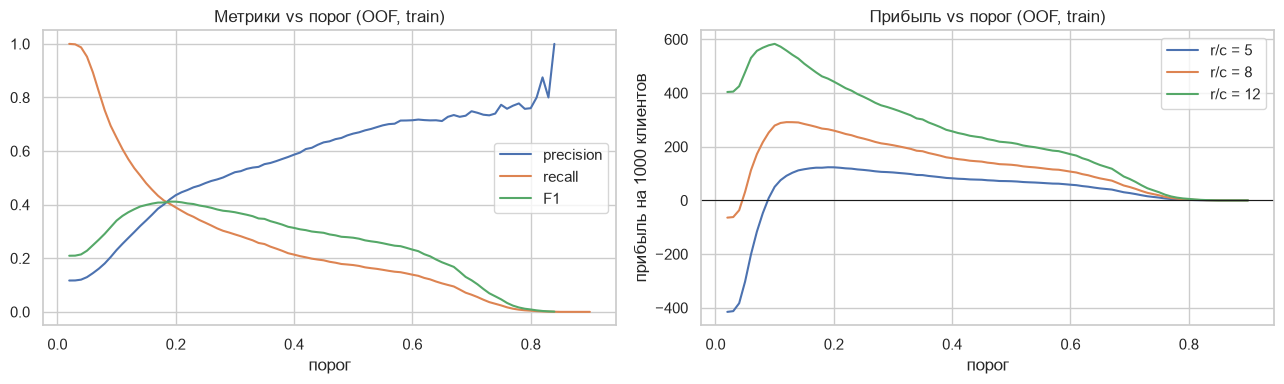

In [19]:
ts = np.linspace(0.02, 0.9, 89)
def profit(p, yy, t, r, c=1.0): return ((p >= t) * (r * yy - c)).sum() / len(yy) * 1000   # прибыль на 1000 клиентов

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
pr_, rc_ = [], []
for t in ts: sel = oof_tr >= t; pr_.append(ytr[sel].mean() if sel.any() else np.nan); rc_.append(ytr[sel].sum() / ytr.sum())
f1_ = 2 * np.array(pr_) * np.array(rc_) / (np.array(pr_) + np.array(rc_) + 1e-12)
axs[0].plot(ts, pr_, label='precision'); axs[0].plot(ts, rc_, label='recall'); axs[0].plot(ts, f1_, label='F1'); axs[0].set_xlabel('порог'); axs[0].legend(); axs[0].set_title('Метрики vs порог (OOF, train)')
for r in (5, 8, 12): axs[1].plot(ts, [profit(oof_tr, ytr, t, r) for t in ts], label=f'r/c = {r}')
axs[1].axhline(0, color='k', lw=.8); axs[1].set_xlabel('порог'); axs[1].set_ylabel('прибыль на 1000 клиентов'); axs[1].legend(); axs[1].set_title('Прибыль vs порог (OOF, train)')
plt.tight_layout(); plt.show()

In [20]:
rows = []
for r in (5, 8, 12):
    t_star = ts[np.argmax([profit(oof_tr, ytr, t, r) for t in ts])]        # порог выбран на train-OOF
    sel = p_te >= t_star; tn, fp, fn, tp = confusion_matrix(yte, sel).ravel()
    rows.append({'r/c': r, 'порог': round(t_star, 2), 'звоним, %': 100 * sel.mean(), 'precision': tp / max(tp + fp, 1), 'recall': tp / (tp + fn),
                 'TP': tp, 'FP': fp, 'FN': fn, 'прибыль модели': profit(p_te, yte, t_star, r),
                 'звонить всем': profit(np.ones(len(yte)), yte, 0.5, r), 'не звонить': 0.0})
thr = pd.DataFrame(rows).set_index('r/c'); thr.round(3)

,порог,"звоним, %",precision,recall,TP,FP,FN,прибыль модели,звонить всем,не звонить
r/c,,,,,,,,,,
5,0.19,11.036,0.432,0.407,431,567,627,127.944,-415.017,0.0
8,0.12,24.450,0.271,0.566,599,1612,459,285.414,-64.027,0.0
12,0.10,33.274,0.232,0.661,699,2310,359,594.825,403.959,0.0


In [21]:
# Для сравнения — порог 0.5 «по умолчанию» и порог по максимуму F1 (train-OOF)
t_f1 = ts[np.nanargmax(f1_)]
rows = []
for name, t in [('порог 0.5 (по умолчанию)', 0.5), (f'порог max F1 ({t_f1:.2f})', t_f1)]:
    sel = p_te >= t; tn, fp, fn, tp = confusion_matrix(yte, sel).ravel()
    rows.append({'порог': name, 'звоним, %': 100 * sel.mean(), 'precision': tp / max(tp + fp, 1), 'recall': tp / (tp + fn), 'TP': tp, 'FP': fp, 'FN': fn,
                 'прибыль r/c=5': profit(p_te, yte, t, 5), 'r/c=8': profit(p_te, yte, t, 8), 'r/c=12': profit(p_te, yte, t, 12)})
pd.DataFrame(rows).set_index('порог').round(3)

,"звоним, %",precision,recall,TP,FP,FN,прибыль r/c=5,r/c=8,r/c=12
порог,,,,,,,,,
порог 0.5 (по умолчанию),3.008,0.676,0.174,184,88,874,71.658,132.699,214.088
порог max F1 (0.19),11.036,0.432,0.407,431,567,627,127.944,270.928,461.572


**Дисбаланс ошибок:** при пороге 0.5 модель почти не звонит (высокая precision, низкий recall): большинство потенциальных «да» превращаются в FN. Чем дороже подписка относительно звонка (`r/c` выше), тем ниже оптимальный порог и тем больше мы готовы терпеть FP.

In [22]:
# Устойчивость порога при смене периода: порог (r/c=8) из train-OOF, применённый к фолдам блочной CV (разные месяцы)
t8 = float(thr.loc[8, 'порог']); o, f = final['block'][1], final['block'][2]; rows = []
for i in sorted(set(f[f >= 0])):
    m = f == i; sel = o[m] >= t8; tp = (y[m][sel]).sum()
    rows.append({'фолд': i, 'доля yes в фолде': y[m].mean(), 'звоним, %': 100 * sel.mean(), 'precision': tp / max(sel.sum(), 1), 'recall': tp / y[m].sum(),
                 'прибыль модели': profit(o[m], y[m], t8, 8), 'звонить всем': profit(np.ones(m.sum()), y[m], .5, 8)})
pd.DataFrame(rows).set_index('фолд').round(3)

,доля yes в фолде,"звоним, %",precision,recall,прибыль модели,звонить всем
фолд,,,,,,
0,0.091,17.948,0.334,0.655,299.426,-268.390
1,0.112,25.444,0.242,0.551,238.327,-105.420
2,0.142,33.207,0.205,0.478,212.047,138.920
3,0.140,31.180,0.280,0.625,386.531,118.043
4,0.100,37.565,0.168,0.632,127.728,-203.279


Если доля «да» в периоде другая, фиксированный порог по вероятности «плавает» (меняется доля обзвона и precision/recall). Поэтому в бою удобнее **правило «звоним топ-k% по модели»** (k подбирается по бюджету обзвона), либо порог нужно периодически пересматривать на свежих данных.

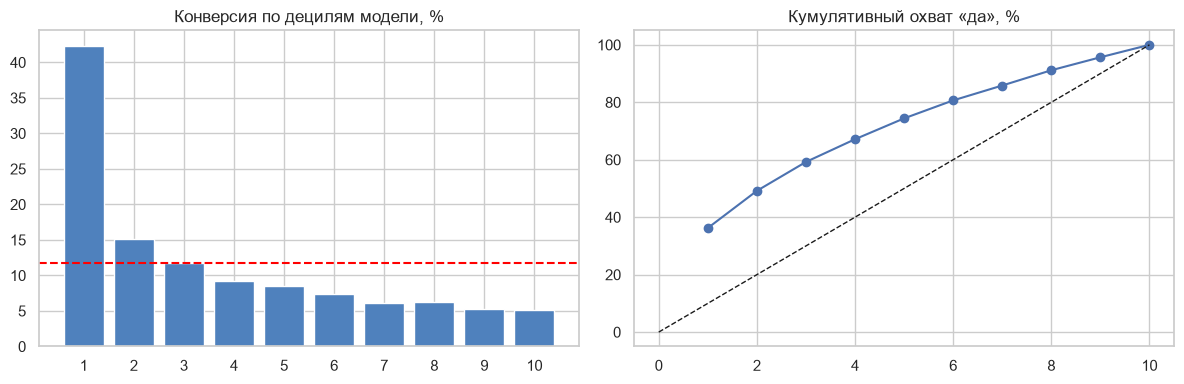

,mean,sum,lift,накоп. доля всех yes
дециль,,,,
1,0.424,1916,3.622,0.362
2,0.152,685,1.295,0.492
3,0.118,532,1.006,0.592
4,0.092,418,0.790,0.671
5,0.085,384,0.726,0.744
6,0.073,331,0.626,0.807
7,0.061,274,0.518,0.858
8,0.062,281,0.531,0.912
9,0.053,239,0.452,0.957


In [23]:
# Lift по децилям (OOF блочной CV — честная оценка): куда звонить в первую очередь
d = pd.DataFrame({'p': final['block'][1], 'y': y}); d['дециль'] = pd.qcut(d.p.rank(method='first', ascending=False), 10, labels=range(1, 11))
g = d.groupby('дециль', observed=True).y.agg(['mean', 'sum']); g['lift'] = g['mean'] / y.mean(); g['накоп. доля всех yes'] = g['sum'].cumsum() / y.sum()
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].bar(g.index.astype(str), g['mean'] * 100, color='#4f81bd'); axs[0].axhline(y.mean() * 100, color='red', ls='--'); axs[0].set_title('Конверсия по децилям модели, %')
axs[1].plot(range(1, 11), g['накоп. доля всех yes'] * 100, 'o-'); axs[1].plot([0, 10], [0, 100], 'k--', lw=1); axs[1].set_title('Кумулятивный охват «да», %')
plt.tight_layout(); plt.show(); g.round(3)

## 10. Вердикт

**Финальная модель — один LightGBM** (без ансамблей): `num_leaves=4`, 400 деревьев, `learning_rate=0.02`, `min_child_samples=100`, `subsample=0.6`, `colsample_bytree=0.5`. Фичи: без `duration` и без прокси периода (`month`, `day`, `contact`, `contact_unknown`). Без ресэмплинга и весов классов. Порог выбирается отдельно по цене ошибок.

| Схема валидации | ROC-AUC | PR-AUC (база 0.117) | Lift@10% |
|---|---|---|---|
| strat (5 фолдов, со стратификацией) — оптимистично | **0.744** | 0.383 | 3.8 |
| block (тест на новых месяцах) — основная | **0.725** | 0.374 | 3.8 |
| time (прошлое → будущее) — строгая | **0.605** | 0.197 | 1.6 |
| стратифицированный hold-out 20% | **0.749** | 0.390 | 3.8 |

Топ-10% клиентов по модели: конверсия ≈ **42%** против 11.7% в среднем, охват ≈ 36% всех «да» (топ-20% → ≈ 49%).

### Что из требований проекта пробовали и что показали
- **Дисбаланс классов** — учтён везде: PR-AUC и Lift вместо accuracy, стратифицированные фолды и hold-out (доля «да» 11.7% в train и test).
- **Взвешивание и сэмплинг (п. 7)** — **не стоит**. Ни один метод не улучшил ранжирование: AUC block 0.725 без балансировки против 0.717–0.724 с ней. При этом `class_weight=balanced` и oversample/undersample 1:1 **портят вероятности** (Brier 0.089 → 0.21), а max F1 не растёт (0.411 → 0.403–0.411). Синтетика **SMOTENC хуже всех** (time AUC 0.549 против 0.604) — на смешанных категориальных фичах интерполяция не имеет смысла. Вывод: данные не пересэмплируем, дисбаланс решается **выбором порога**.
- **Порог и цена ошибок (п. 9)** — **стоит, и это главный рычаг.** Порог 0.5 «по умолчанию» звонит лишь 3% клиентов (recall 17%) и приносит меньше половины возможной прибыли. При иллюстративной цене (звонок `c=1`, подписка `r`):
  - `r/c=5`: порог 0.19, звоним 11%, precision 43%, recall 41%, прибыль 128 на 1000 клиентов (звонить всем: −415);
  - `r/c=8`: порог 0.12, звоним 24%, precision 27%, recall 57%, прибыль 285 (всем: −64);
  - `r/c=12`: порог 0.10, звоним 33%, recall 66%, прибыль 595 (всем: 404).
  Порог выбирался по train-OOF и применён к test. «Звонить всем» выгодно только при `r/c > ≈8.5`.
- **Дисбаланс ошибок:** при разумном пороге FP в 2–3 раза больше TP (precision 23–43%) — это осознанная цена за высокий recall; FN обходятся дороже, чем FP, когда `r/c` велик.
- **Признаки через призму классов:** EDA (конверсия по группам) + распределения по классам в п. 8; ключевое: `poutcome`, `prev_success`, `n_loans`, `pdays_clean`, `age`.

### Ограничения
- **Цены ошибок `r` и `c` — иллюстративные**; для реальной цифры нужны данные банка. Таблицу в п. 9 надо пересчитать на настоящем `r/c`.
- **Порог по вероятности нестабилен при смене периода:** на блочных фолдах доля обзвона колеблется 18–38%, precision 17–33% (доля «да» в периодах 9–14%). Прибыль модели при этом положительна и выше «звонить всем» во всех 5 фолдах, но в бою лучше правило «звоним топ-k% по модели» или периодический пересмотр порога.
- **Строгая схема time слабая:** первые три фолда (только 2008 год) ≈ 0.55, поздние ≈ 0.67 — модель не переносит резкую смену политики обзвона. На новом периоде реалистично ждать AUC 0.6–0.73.
- Отложенного теста вне CV нет: параметры подбирались по CV на всех данных, hold-out в п. 9 использовался для порога, а не для выбора модели (небольшой оптимизм остаётся).

**Дальше:** калибровка вероятностей (isotonic/Platt) для более стабильного порога; обсудить с командой реальные `r` и `c`; проверка на более поздних данных, если появятся.



## 11. Обновление после клиентского анализа
Позже (см. [clients_levin.ipynb](clients_levin.ipynb) и [final_levin.ipynb](final_levin.ipynb)) конфигурация уточнена: убран `campaign` (формально «из будущего»), добавлена история клиента на момент звонка, валидация только по времени. Честная оценка на новых периодах: **AUC ≈ 0,60 (весь датасет), ≈ 0,63 (тест на 2009+)**; цифры 0,744 / 0,725 выше завышены прокси периода. Выводы этого ноутбука про валидацию, имбаланс и порог остаются в силе.